In [2]:
import os,  json

import pandas as pd
import numpy as np
import xarray as xr 

from sklearn.linear_model import LassoCV
from sklearn.model_selection import GroupKFold
from sklearn.preprocessing import StandardScaler

import matplotlib.pyplot as plt

import pickle

from xgboost import XGBRegressor


#### Load Data

In [3]:
point = 'p102'
pcs_df = pd.read_csv('outputs/pca/pcs_msl_100.csv', index_col =0, parse_dates=True)
waves_z_df = pd.read_csv(f'outputs/marginal/z_bulk_{point}.csv', index_col =0, parse_dates = True)

pit_transform = pd.read_pickle(f'outputs/marginal/transformacion_{point}.pkl')

#### Outputs Pahts
output_p = 'outputs/selection'
os.makedirs(output_p, exist_ok=True)
#### Parameters
train_start = '1985-01-01'
train_end = '2016-01-01'

lags = [0, 6, 12, 18, 24, 30, 36]
n_pcs_retained = [5, 10, 15, 20, 25, 30, 35, 40, 50, 100]
seed = 0
max_iter = 40000

#### Build 6h Predictor and Predictand

In [4]:
pcs_msl_lagged = pd.concat({f"l{l}": pcs_df.shift(freq=pd.Timedelta(hours=l)) for l in lags}, axis=1).reindex(pcs_df.index)
pcs_msl_lagged.columns = [f"{c}_l{l[1:]}" for l, c in pcs_msl_lagged.columns]
pcs_msl_lagged = pcs_msl_lagged.dropna()         
print(pcs_msl_lagged.shape)  

seis = lambda idx: idx[idx.hour.isin([0, 6, 12, 18])]

z6 = waves_z_df["VHM0"].rolling("6h", center=True).mean()

idx = seis(pcs_msl_lagged.index.intersection(z6.dropna().index))
idx_train = idx[(idx >= train_start) & (idx < train_end)]

X_train = pcs_msl_lagged.loc[idx_train]
y_train = z6.loc[idx_train]

(761148, 700)


In [5]:
group_kfold = GroupKFold(n_splits=5, shuffle=True, random_state=seed)
groups = y_train.index.year
group_kfold.split(X_train, y_train, groups)

<generator object _BaseKFold.split at 0x0000026F480556C0>

In [6]:
scaler = StandardScaler().fit(X_train)
X_train_s = scaler.transform(X_train)

In [7]:
cv_split_list = list(group_kfold.split(X_train, y_train, groups))
lasso_crossval = LassoCV(max_iter=max_iter, cv=cv_split_list, n_jobs=-1)
lasso_crossval.fit(X=X_train_s, y=y_train)

,"max_iter max_iter: int, default=1000The maximum number of iterations.",40000
,"cv cv: int, cross-validation generator or iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross-validation,- int, to specify the number of folds,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For int/None inputs, :class:`~sklearn.model_selection.KFold` is used.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.","[(array([ 0,...hape=(35064,)), ...), (array([ 0,...hape=(36520,)), ...), ...]"
,"n_jobs n_jobs: int, default=NoneNumber of CPUs to use during the cross validation.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",-1
,"eps eps: float, default=1e-3Length of the path. ``eps=1e-3`` means that``alpha_min / alpha_max = 1e-3``.",0.001
,"alphas alphas: array-like or int, default=100Values of alphas to test along the regularization path.If int, `alphas` values are generated automatically.If array-like, list of alpha values to use... versionchanged:: 1.7 `alphas` accepts an integer value which removes the need to pass `n_alphas`.",100
,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto false, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"precompute precompute: 'auto', bool or array-like of shape (n_features, n_features), default='auto'Whether to use a precomputed Gram matrix to speed upcalculations. If set to ``'auto'`` let us decide. The Grammatrix can also be passed as an argument.",'auto'
,"tol tol: float, default=1e-4The tolerance for the optimization: if the updates are smaller or equal to``tol``, the optimization code checks the dual gap for optimality and continuesuntil it is smaller or equal to ``tol``.",0.0001
,"copy_X copy_X: bool, default=TrueIf ``True``, `X` will be copied; otherwise, it may be overwritten.",True
,"verbose verbose: bool or int, default=FalseAmount of verbosity.",False
,"positive positive: bool, default=FalseIf positive, restrict regression coefficients to be positive.",False


In [8]:
lasso_coefs_df = pd.DataFrame(lasso_crossval.coef_.reshape(7, 100),
                              index=lags, columns=pcs_df.columns)

importance = lasso_coefs_df.abs().sum().sort_values(ascending=False)

In [9]:
print(f"alpha = {lasso_crossval.alpha_:.2e} | coef != 0: {(lasso_crossval.coef_ != 0).sum()} of 700")
print(f"PCs with some nonzero coef: {(importance > 0).sum()} of 100")

alpha = 4.09e-04 | coef != 0: 578 of 700
PCs with some nonzero coef: 100 of 100


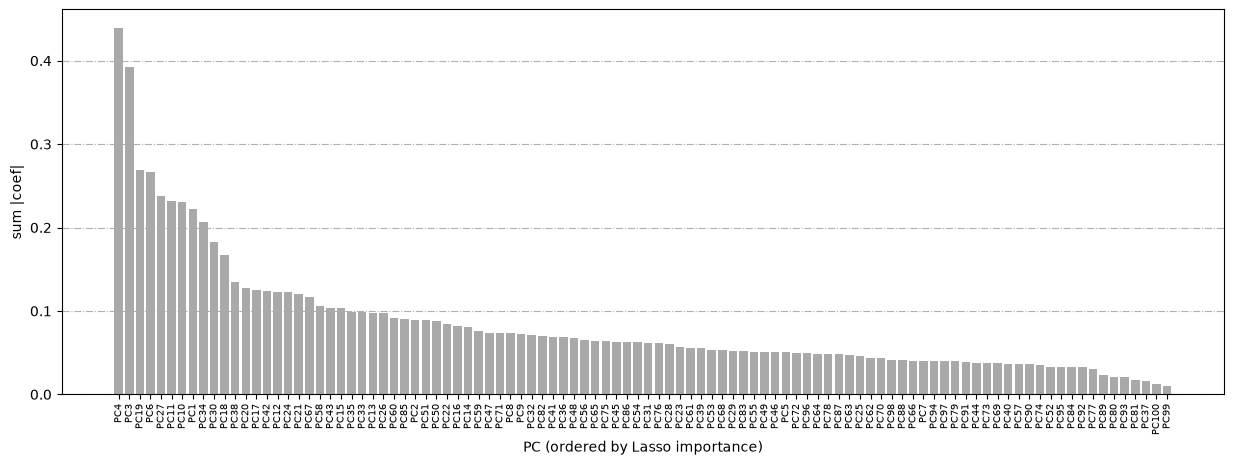

In [10]:
fig, ax = plt.subplots(1, 1, figsize=(15, 5))
ax.bar(x=range(100), height=importance.values, color='darkgray')
ax.set_xticks(range(100))
ax.set_xticklabels(importance.index.str.replace('msl_', ''), rotation=90, fontsize=7)
ax.grid(axis='y', linestyle='-.')
ax.set_axisbelow(True)
ax.set_ylabel('sum |coef|')
ax.set_xlabel('PC (ordered by Lasso importance)')
fig.savefig(f"{output_p}/ranking_lasso.png", dpi=150)
plt.show()

In [11]:
xgb_params = dict(n_estimators=300, learning_rate=0.05, max_depth=3, min_child_weight=200,
                subsample=0.8, colsample_bytree=0.8, tree_method="hist",
                n_jobs=-1, random_state=seed)

oof_preds = {}
for k in n_pcs_retained:
    pcs_retained = importance.index[:k]
    cols = [c for c in X_train.columns if c.rsplit("_l", 1)[0] in pcs_retained]

    f = pd.Series(np.nan, index=X_train.index)
    for i_fit, i_val in cv_split_list:
        model = XGBRegressor(**xgb_params).fit(X_train.iloc[i_fit][cols], y_train.iloc[i_fit])
        f.iloc[i_val] = model.predict(X_train.iloc[i_val][cols])

    oof_preds[k] = f
    print(k, len(cols), f"corr OOF {f.corr(y_train):.3f}", flush=True)

5 35 corr OOF 0.547
10 70 corr OOF 0.653
15 105 corr OOF 0.674
20 140 corr OOF 0.683
25 175 corr OOF 0.691
30 210 corr OOF 0.732
35 245 corr OOF 0.733
40 280 corr OOF 0.740
50 350 corr OOF 0.743
100 700 corr OOF 0.744


#### Export Outputs

In [12]:
k_sel = 30
pcs_sel = importance.index[:k_sel].tolist()

# 1. Selected PCs, hourly, full period (1940–2026): this is what the 03 PVAR and the 04 XGB read
pcs_df[pcs_sel].to_csv(f"{output_p}/pcs_msl_sel_lasso{k_sel}.csv")

# 2. Full ranking, curve and folds (for the record and for reusing the folds)
importance.rename("sum_abs_coef").to_csv(f"{output_p}/ranking_lasso.csv")
pd.Series({k: f.corr(y_train) for k, f in oof_preds.items()}, name="corr_oof").rename_axis("k").to_csv(f"{output_p}/curve_k.csv")

year_fold = {int(y): i for i, (_, te) in enumerate(cv_split_list) for y in set(groups[te])}
pd.Series(year_fold, name="fold").rename_axis("year").sort_index().to_csv(f"{output_p}/cv_folds_years.csv")

# 3. Record of the decision
json.dump({
    "pcs": pcs_sel,
    "k": k_sel,
    "k_reason": "limited by the dimension of the PVAR; plateau of the OOF curve from k=30",
    "ranking": "LassoCV (GroupKFold by year, 5 folds), sum |coef| over lags 0–36 h",
    "alpha": float(lasso_crossval.alpha_),
    "train": [train_start, train_end],
    "point": point,
    "xgb_curve": xgb_params,
}, open(f"{output_p}/selection.json", "w"), indent=2)

print(len(pcs_sel), "PCs saved | PC2 included:", "msl_PC2" in pcs_sel)

30 PCs saved | PC2 included: True
